# Customer Analytics & Churn Prediction
## End-to-End ML Pipeline — Observation/Performance Window Split

**Objective:** Build a production-grade churn prediction model using proper ML methodology.

**Key Design:** Features are built from an *observation window* (historical behavior).  
The *performance window* (last 90 days) is used only to define the churn label.  
This eliminates data leakage and produces honest, interpretable model performance.

| Window | Period | Purpose |
|--------|--------|---------|
| Observation | Signup → 2025-04-01 | Build features (all behavior history) |
| Performance | 2025-04-01 → 2025-06-30 | Define churn label (bought or not?) |

**Tools:** Python · pandas · scikit-learn · matplotlib · seaborn · openpyxl  
**Dataset:** 600 customers · ~4,000 orders · ~3,000 interactions  
**Ground Truth:** `churn_flag` saved in `customers.csv` at data-generation time

In [1]:
# Step 1: Imports & Configuration
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, GridSearchCV)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve,
                             precision_recall_curve, average_precision_score,
                             ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')

# ── Path resolution (works from project root OR notebooks/) ──
if os.path.exists('data'):
    DATA_DIR, OUTPUT_DIR = 'data', 'outputs'
elif os.path.exists('../data'):
    DATA_DIR, OUTPUT_DIR = '../data', '../outputs'
else:
    DATA_DIR, OUTPUT_DIR = 'data', 'outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ── Time window constants ──
REFERENCE_DATE    = pd.Timestamp('2025-06-30')
PERF_WINDOW_START = pd.Timestamp('2025-04-01')   # REFERENCE_DATE − 90 days
PERF_WINDOW_DAYS  = (REFERENCE_DATE - PERF_WINDOW_START).days

# ── Plot style ──
sns.set_style('whitegrid')
sns.set_palette('husl')
plt.rcParams.update({'font.size': 11, 'figure.dpi': 100})

print('✓ Imports complete')
print(f'  Observation window: signup date  →  {PERF_WINDOW_START.date()}')
print(f'  Performance window: {PERF_WINDOW_START.date()}  →  {REFERENCE_DATE.date()} ({PERF_WINDOW_DAYS} days)')
print(f'  Data  dir: {os.path.abspath(DATA_DIR)}')
print(f'  Output dir: {os.path.abspath(OUTPUT_DIR)}')

✓ Imports complete
  Observation window: signup date  →  2025-04-01
  Performance window: 2025-04-01  →  2025-06-30 (90 days)
  Data  dir: C:\Users\ashis\Desktop\Customer_Analytics_Project\data
  Output dir: C:\Users\ashis\Desktop\Customer_Analytics_Project\outputs


## 1. Data Loading

Three relational tables loaded from CSV. `customers.csv` contains the **pre-assigned `churn_flag`** — the ground truth label generated independently of purchase recency to avoid data leakage.

In [2]:
# Step 2: Load Raw Data
customers_df     = pd.read_csv(os.path.join(DATA_DIR, 'customers.csv'),
                               parse_dates=['signup_date'])
orders_df        = pd.read_csv(os.path.join(DATA_DIR, 'orders.csv'),
                               parse_dates=['order_date'])
interactions_df  = pd.read_csv(os.path.join(DATA_DIR, 'customer_interactions.csv'),
                               parse_dates=['interaction_date'])

print(f'Customers:    {customers_df.shape[0]:>5} rows × {customers_df.shape[1]} cols')
print(f'Orders:       {orders_df.shape[0]:>5} rows × {orders_df.shape[1]} cols')
print(f'Interactions: {interactions_df.shape[0]:>5} rows × {interactions_df.shape[1]} cols')

# Verify ground-truth label exists
assert 'churn_flag' in customers_df.columns, "churn_flag missing from customers.csv!"
churn_rate = customers_df['churn_flag'].mean() * 100
print(f'\nGround-truth churn rate: {churn_rate:.1f}%')
print(f'  Churned  : {customers_df["churn_flag"].sum()}')
print(f'  Active   : {(customers_df["churn_flag"] == 0).sum()}')
display(customers_df.head(3))

Customers:      600 rows × 8 cols
Orders:        5743 rows × 7 cols
Interactions:  3771 rows × 6 cols

Ground-truth churn rate: 29.0%
  Churned  : 174
  Active   : 426


,customer_id,customer_name,email,signup_date,country,age,gender,churn_flag
0,1001,Meera Patel,customer1001@email.com,2023-04-18,Germany,33,M,0
1,1002,Kiran Zhang,customer1002@email.com,2024-09-11,Mexico,23,F,1
2,1003,Amit Reddy,customer1003@email.com,2024-12-30,Australia,32,M,1


In [3]:
# Step 3: Data Quality Check
print('=== MISSING VALUES ===')
for name, df in [('Customers', customers_df), ('Orders', orders_df),
                 ('Interactions', interactions_df)]:
    missing = df.isnull().sum().sum()
    dupes   = df.duplicated().sum()
    print(f'  {name:15s}: {df.shape[0]:>5} rows, {missing} missing, {dupes} duplicates')

print('\n=== ORDER AMOUNT DISTRIBUTION (log-normal) ===')
print(orders_df['order_amount'].describe().round(2))
print(f'  Median: ${orders_df["order_amount"].median():.2f}  '
      f'Skew: {orders_df["order_amount"].skew():.2f}')

print('\n=== ORDER STATUS ===')
print(orders_df['order_status'].value_counts().to_string())

=== MISSING VALUES ===


  Customers      :   600 rows, 0 missing, 0 duplicates
  Orders         :  5743 rows, 0 missing, 0 duplicates
  Interactions   :  3771 rows, 0 missing, 0 duplicates

=== ORDER AMOUNT DISTRIBUTION (log-normal) ===
count    5743.00
mean      199.50
std       188.22
min        15.00
25%        85.14
50%       145.25
75%       246.41
max      2500.00
Name: order_amount, dtype: float64
  Median: $145.25  Skew: 3.28

=== ORDER STATUS ===
order_status
Completed    4501
Pending       556
Cancelled     414
Returned      272


## 2. Observation / Performance Window Split

**This is the most critical step** — it eliminates data leakage.

- **Observation window** orders → used to build ALL features
- **Performance window** orders → used ONLY to verify label alignment (not in features)

The churn label comes from `churn_flag` in `customers.csv` (independent ground truth).

In [4]:
# Step 4: Split Orders by Window
obs_orders  = orders_df[orders_df['order_date'] <  PERF_WINDOW_START].copy()
perf_orders = orders_df[orders_df['order_date'] >= PERF_WINDOW_START].copy()

print(f'Observation window orders : {len(obs_orders):>5}  ({len(obs_orders)/len(orders_df)*100:.1f}%)')
print(f'Performance window orders : {len(perf_orders):>5}  ({len(perf_orders)/len(orders_df)*100:.1f}%)')

# How many customers have at least 1 performance-window purchase?
perf_buyers = set(perf_orders['customer_id'].unique())
n_perf_buyers = sum(1 for cid in customers_df['customer_id'] if cid in perf_buyers)
print(f'\nCustomers with perf-window purchase: {n_perf_buyers} '
      f'({n_perf_buyers/len(customers_df)*100:.1f}%)')

# ── Label alignment check: churn_flag vs recency-based label ──
# This shows WHY we use churn_flag instead of recency > 90
recency_label = (~customers_df['customer_id'].isin(perf_buyers)).astype(int)
agreement = (recency_label == customers_df['churn_flag']).mean() * 100
noise_pct  = 100 - agreement
print(f'\nLabel alignment (churn_flag vs recency-based): {agreement:.1f}%')
print(f'Noise level (intentional disagreement)        : {noise_pct:.1f}%')
print('  → Noise ensures the model must LEARN patterns, not memorise a threshold rule.')

Observation window orders :  4391  (76.5%)
Performance window orders :  1352  (23.5%)

Customers with perf-window purchase: 418 (69.7%)

Label alignment (churn_flag vs recency-based): 85.3%
Noise level (intentional disagreement)        : 14.7%
  → Noise ensures the model must LEARN patterns, not memorise a threshold rule.


## 3. Feature Engineering (Observation Window Only)

All features are computed from orders/interactions **before `PERF_WINDOW_START`**.  
The performance window data is not touched until model evaluation.

| Feature | Description |
|---------|-------------|
| `obs_purchase_count` | Total orders in observation window |
| `obs_total_spent` | Total spending in observation window |
| `obs_avg_order_value` | Average order value (median-imputed if no orders) |
| `obs_recency_days` | Days since last obs-window order (from PERF_WINDOW_START) |
| `obs_purchase_freq_monthly` | Orders per month in observation window |
| `obs_spend_rate_daily` | Daily avg spending in observation window |
| `obs_interaction_count` | Total interactions in observation window |
| `obs_interaction_rate` | Interactions per month in observation window |
| `tenure_at_perf_start` | Customer age (days) at PERF_WINDOW_START |
| `has_ordered_in_obs` | Binary: did they order at all before the window? |

In [5]:
# Step 5: Purchase Features from Observation Window
obs_purchase = obs_orders.groupby('customer_id').agg(
    obs_purchase_count    = ('order_id',     'count'),
    obs_total_spent       = ('order_amount', 'sum'),
    obs_avg_order_value   = ('order_amount', 'mean'),
    obs_last_order_date   = ('order_date',   'max'),
    obs_first_order_date  = ('order_date',   'min')
).reset_index()

print(f'Customers with obs-window orders: {len(obs_purchase)}')
print(obs_purchase[['obs_purchase_count','obs_total_spent','obs_avg_order_value']].describe().round(2))

Customers with obs-window orders: 600
       obs_purchase_count  obs_total_spent  obs_avg_order_value
count              600.00           600.00               600.00
mean                 7.32          1460.13               197.98
std                  3.77           901.14                80.92
min                  1.00            15.00                15.00
25%                  4.00           718.70               150.32
50%                  7.00          1299.33               186.53
75%                 10.25          2068.80               236.52
max                 14.00          4839.86               780.95


In [6]:
# Step 6: Interaction Features from Observation Window
obs_interactions = interactions_df[
    interactions_df['interaction_date'] < PERF_WINDOW_START
].copy()

obs_interact = obs_interactions.groupby('customer_id').agg(
    obs_interaction_count = ('interaction_id',  'count'),
    obs_last_interact_date = ('interaction_date', 'max')
).reset_index()

print(f'Customers with obs-window interactions: {len(obs_interact)}')

Customers with obs-window interactions: 584


In [7]:
# Step 7: Merge All Features into Master DataFrame
master_df = customers_df[['customer_id', 'customer_name', 'email',
                           'signup_date', 'country', 'age', 'gender',
                           'churn_flag']].copy()

master_df = master_df.merge(obs_purchase,  on='customer_id', how='left')
master_df = master_df.merge(obs_interact,  on='customer_id', how='left')

# ── Tenure at performance window start ──
master_df['tenure_at_perf_start'] = (
    PERF_WINDOW_START - master_df['signup_date']
).dt.days.clip(lower=1)

# ── Fill missing for no-purchase customers ──
master_df['obs_purchase_count']   = master_df['obs_purchase_count'].fillna(0).astype(int)
master_df['obs_total_spent']      = master_df['obs_total_spent'].fillna(0.0)
master_df['obs_interaction_count'] = master_df['obs_interaction_count'].fillna(0).astype(int)

# ── avg_order_value: use dataset median for no-purchase customers (not 0) ──
aov_median = master_df['obs_avg_order_value'].median()
master_df['obs_avg_order_value'] = master_df['obs_avg_order_value'].fillna(aov_median)
print(f'avg_order_value imputed with dataset median: ${aov_median:.2f}')

# ── Binary flag: has ordered at all? ──
master_df['has_ordered_in_obs'] = (master_df['obs_purchase_count'] > 0).astype(int)

# ── Recency: days since last obs-window order (measured from PERF_WINDOW_START) ──
master_df['obs_recency_days'] = (
    PERF_WINDOW_START - master_df['obs_last_order_date']
).dt.days
# Customers with NO obs orders → recency = their full tenure (very inactive)
master_df['obs_recency_days'] = master_df['obs_recency_days'].fillna(
    master_df['tenure_at_perf_start']
)

# ── Purchase frequency per month in obs window ──
master_df['obs_purchase_freq_monthly'] = (
    master_df['obs_purchase_count'] /
    (master_df['tenure_at_perf_start'] / 30).clip(lower=1)
)

# ── Spend rate per day in obs window ──
master_df['obs_spend_rate_daily'] = (
    master_df['obs_total_spent'] /
    master_df['tenure_at_perf_start'].clip(lower=1)
)

# ── Interaction rate per month ──
master_df['obs_interaction_rate'] = (
    master_df['obs_interaction_count'] /
    (master_df['tenure_at_perf_start'] / 30).clip(lower=1)
)

print(f'\nMaster dataframe: {master_df.shape}')
print(f'  Customers with obs orders     : {master_df["has_ordered_in_obs"].sum()}')
print(f'  Customers without obs orders  : {(master_df["has_ordered_in_obs"] == 0).sum()}')
print(f'  Churn flag distribution:\n{master_df["churn_flag"].value_counts().to_string()}')

avg_order_value imputed with dataset median: $186.53

Master dataframe: (600, 21)
  Customers with obs orders     : 600
  Customers without obs orders  : 0
  Churn flag distribution:
churn_flag
0    426
1    174


## 4. RFM Analysis & Customer Segmentation

RFM scores are computed on the **training set** and applied to the test set using percentile rank transformation. This prevents leakage of test-set distribution into the scoring.

> **Note:** RFM is used here for business insight and segmentation only, NOT as ML features (which would create a circular dependency since RFM scores rank customers relative to each other).

In [8]:
# Step 8: RFM Calculation (for business segmentation, not ML features)
# RFM uses full obs-window metrics for all 600 customers
# This is correct for business reporting — but RFM scores are NOT used as ML features

rfm = master_df[['customer_id', 'obs_recency_days',
                 'obs_purchase_count', 'obs_total_spent']].copy()
rfm.columns = ['customer_id', 'recency', 'frequency', 'monetary']

# Assign quintile scores on FULL data (for segmentation only, not prediction)
# Recency: lower is better → reverse scoring
def safe_qcut(series, n, labels, reverse=False):
    ranked = series.rank(method='first', ascending=not reverse)
    return pd.qcut(ranked, n, labels=labels, duplicates='drop').astype(float)

rfm['R'] = safe_qcut(rfm['recency'],   5, [5,4,3,2,1], reverse=False)  # lower recency = score 5
rfm['F'] = safe_qcut(rfm['frequency'], 5, [1,2,3,4,5], reverse=True)
rfm['M'] = safe_qcut(rfm['monetary'],  5, [1,2,3,4,5], reverse=True)
rfm['rfm_score'] = rfm['R'] + rfm['F'] + rfm['M']

def rfm_segment(score):
    if score >= 12: return 'Champions'
    elif score >= 9: return 'Loyal'
    elif score >= 6: return 'At Risk'
    else:            return 'Lost'

rfm['rfm_segment'] = rfm['rfm_score'].apply(rfm_segment)

master_df = master_df.merge(rfm[['customer_id','R','F','M','rfm_score','rfm_segment']],
                            on='customer_id', how='left')

print('RFM segments:')
print(master_df['rfm_segment'].value_counts().to_string())
print(f'\nChurn rate by segment:')
print(master_df.groupby('rfm_segment')['churn_flag'].mean().mul(100).round(1).to_string())

RFM segments:
rfm_segment
Loyal        238
At Risk      196
Champions    103
Lost          63

Churn rate by segment:
rfm_segment
At Risk      10.7
Champions    55.3
Lost          0.0
Loyal        40.3


## 5. Exploratory Data Analysis

Understanding behavioral differences between churned and active customers **in the observation window** — before seeing the performance window outcome.

✓ Saved 01_EDA_Analysis.png


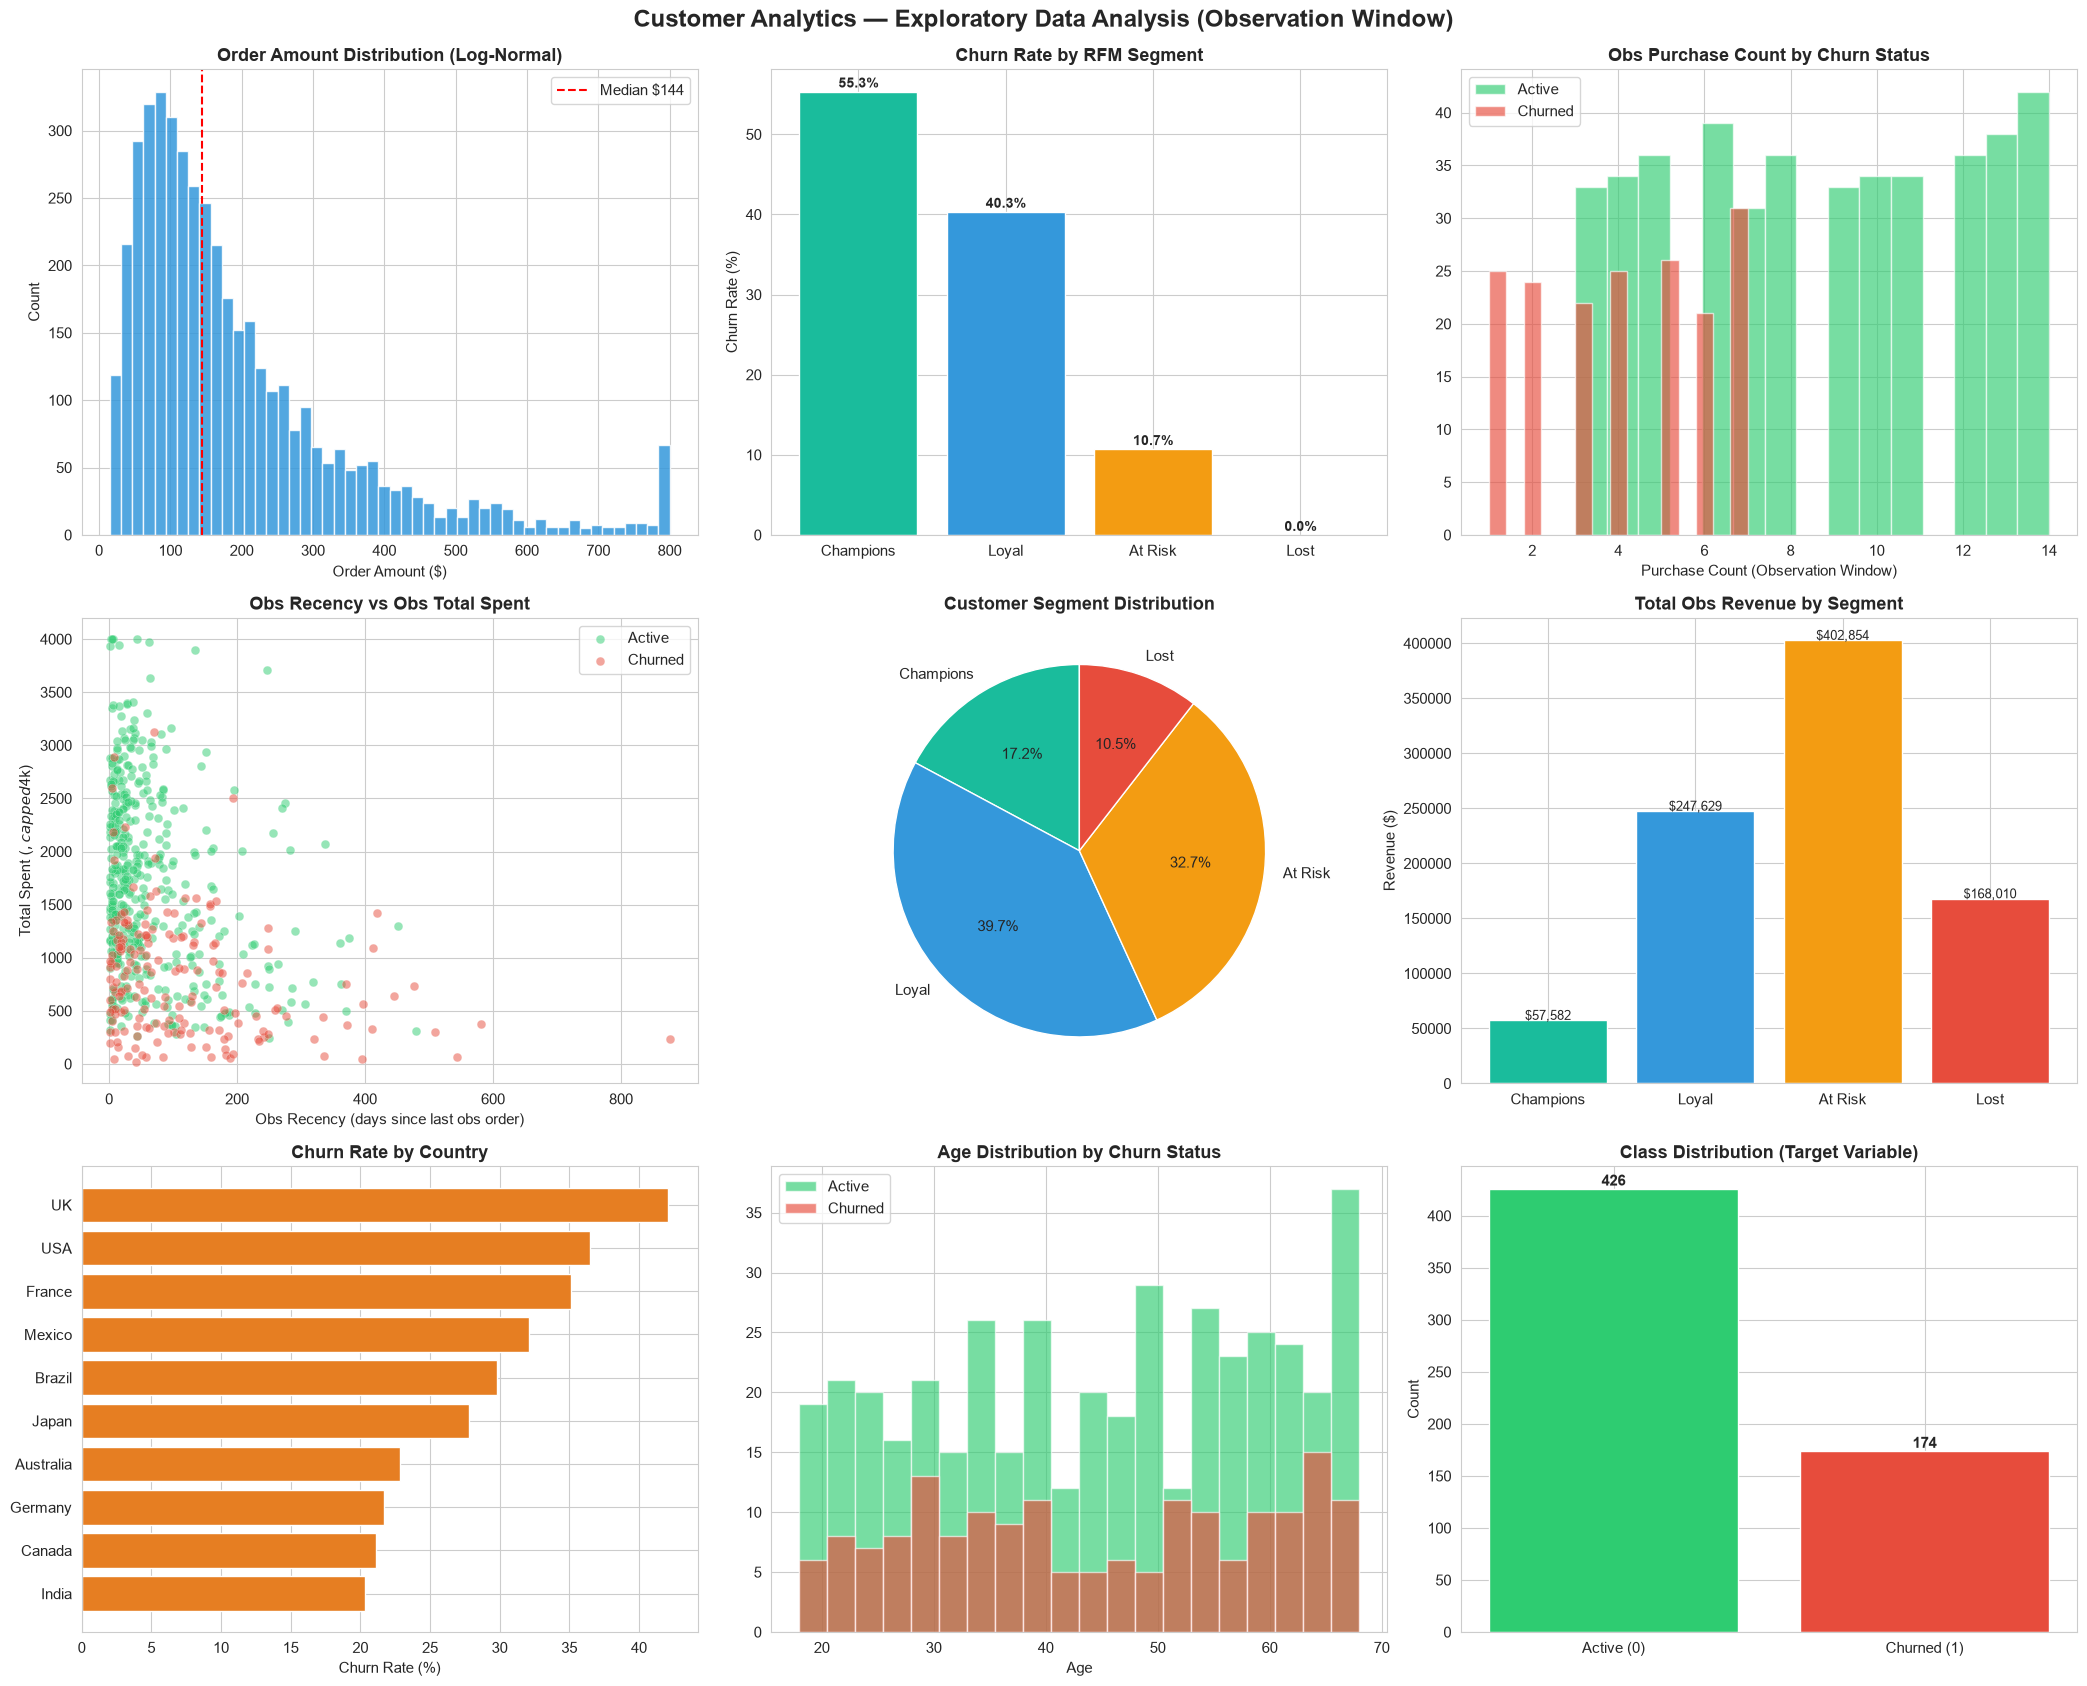

In [9]:
# Step 9: 9-Panel EDA
fig, axes = plt.subplots(3, 3, figsize=(21, 17))
fig.suptitle('Customer Analytics — Exploratory Data Analysis (Observation Window)',
             fontsize=17, fontweight='bold', y=0.99)

colors_churn = {0: '#2ecc71', 1: '#e74c3c'}
seg_order  = ['Champions', 'Loyal', 'At Risk', 'Lost']
seg_colors = ['#1abc9c', '#3498db', '#f39c12', '#e74c3c']

# 1. Order amount distribution (log-normal)
axes[0,0].hist(obs_orders['order_amount'].clip(upper=800),
               bins=50, color='#3498db', edgecolor='white', alpha=0.85)
axes[0,0].set_title('Order Amount Distribution (Log-Normal)', fontweight='bold')
axes[0,0].set_xlabel('Order Amount ($)')
axes[0,0].set_ylabel('Count')
axes[0,0].axvline(obs_orders['order_amount'].median(), color='red',
                  linestyle='--', label=f'Median ${obs_orders["order_amount"].median():.0f}')
axes[0,0].legend()

# 2. Churn rate by RFM segment
churn_seg = master_df.groupby('rfm_segment')['churn_flag'].mean() * 100
churn_seg = churn_seg.reindex(seg_order)
bars = axes[0,1].bar(churn_seg.index, churn_seg.values, color=seg_colors, edgecolor='white')
axes[0,1].set_title('Churn Rate by RFM Segment', fontweight='bold')
axes[0,1].set_ylabel('Churn Rate (%)')
for bar, val in zip(bars, churn_seg.values):
    if not np.isnan(val):
        axes[0,1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
                      f'{val:.1f}%', ha='center', fontweight='bold', fontsize=10)

# 3. Obs purchase count — churned vs active
for flag, color, label in [(0,'#2ecc71','Active'),(1,'#e74c3c','Churned')]:
    axes[0,2].hist(master_df[master_df['churn_flag']==flag]['obs_purchase_count'],
                   bins=15, alpha=0.65, color=color, label=label, edgecolor='white')
axes[0,2].set_title('Obs Purchase Count by Churn Status', fontweight='bold')
axes[0,2].set_xlabel('Purchase Count (Observation Window)')
axes[0,2].legend()

# 4. Obs recency vs total spent (scatter, by churn)
for flag, color, label in [(0,'#2ecc71','Active'),(1,'#e74c3c','Churned')]:
    sub = master_df[master_df['churn_flag'] == flag]
    axes[1,0].scatter(sub['obs_recency_days'], sub['obs_total_spent'].clip(upper=4000),
                      c=color, s=40, alpha=0.5, label=label, edgecolors='white', linewidth=0.3)
axes[1,0].set_title('Obs Recency vs Obs Total Spent', fontweight='bold')
axes[1,0].set_xlabel('Obs Recency (days since last obs order)')
axes[1,0].set_ylabel('Total Spent ($, capped $4k)')
axes[1,0].legend()

# 5. RFM segment distribution
seg_counts = master_df['rfm_segment'].value_counts().reindex(seg_order)
axes[1,1].pie(seg_counts.values, labels=seg_counts.index, colors=seg_colors,
              autopct='%1.1f%%', startangle=90, textprops={'fontsize':11})
axes[1,1].set_title('Customer Segment Distribution', fontweight='bold')

# 6. Revenue by segment (obs window only)
rev_seg = master_df.groupby('rfm_segment')['obs_total_spent'].sum().reindex(seg_order)
bars = axes[1,2].bar(rev_seg.index, rev_seg.values, color=seg_colors, edgecolor='white')
axes[1,2].set_title('Total Obs Revenue by Segment', fontweight='bold')
axes[1,2].set_ylabel('Revenue ($)')
for bar, val in zip(bars, rev_seg.values):
    if not np.isnan(val):
        axes[1,2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+200,
                      f'${val:,.0f}', ha='center', fontsize=9)

# 7. Churn rate by country
churn_country = master_df.groupby('country')['churn_flag'].mean() * 100
churn_country = churn_country.sort_values()
axes[2,0].barh(churn_country.index, churn_country.values, color='#e67e22', edgecolor='white')
axes[2,0].set_title('Churn Rate by Country', fontweight='bold')
axes[2,0].set_xlabel('Churn Rate (%)')

# 8. Age distribution by churn
for flag, color, label in [(0,'#2ecc71','Active'),(1,'#e74c3c','Churned')]:
    master_df[master_df['churn_flag']==flag]['age'].hist(
        ax=axes[2,1], bins=20, alpha=0.65, color=color, label=label, edgecolor='white')
axes[2,1].set_title('Age Distribution by Churn Status', fontweight='bold')
axes[2,1].set_xlabel('Age')
axes[2,1].legend()

# 9. Active vs Churned count
churn_counts = master_df['churn_flag'].value_counts()
bars = axes[2,2].bar(['Active (0)', 'Churned (1)'],
                     [churn_counts.get(0,0), churn_counts.get(1,0)],
                     color=['#2ecc71','#e74c3c'], edgecolor='white')
axes[2,2].set_title('Class Distribution (Target Variable)', fontweight='bold')
axes[2,2].set_ylabel('Count')
for bar in bars:
    axes[2,2].text(bar.get_x()+bar.get_width()/2, bar.get_height()+3,
                  f'{int(bar.get_height())}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'01_EDA_Analysis.png'), dpi=150, bbox_inches='tight')
print(f'✓ Saved 01_EDA_Analysis.png')
plt.show()

✓ Saved 02_Correlation_Matrix.png

📊 Top correlations with churn_flag:
  obs_purchase_count             -0.548  (↓ negative)
  obs_interaction_count          -0.482  (↓ negative)
  obs_total_spent                -0.464  (↓ negative)
  obs_purchase_freq_monthly      -0.249  (↓ negative)
  obs_spend_rate_daily           -0.246  (↓ negative)
  obs_interaction_rate           -0.245  (↓ negative)
  obs_recency_days               +0.242  (↑ positive)
  obs_avg_order_value            -0.039  (↓ negative)
  tenure_at_perf_start           +0.002  (↑ positive)
  has_ordered_in_obs             +nan  (↓ negative)


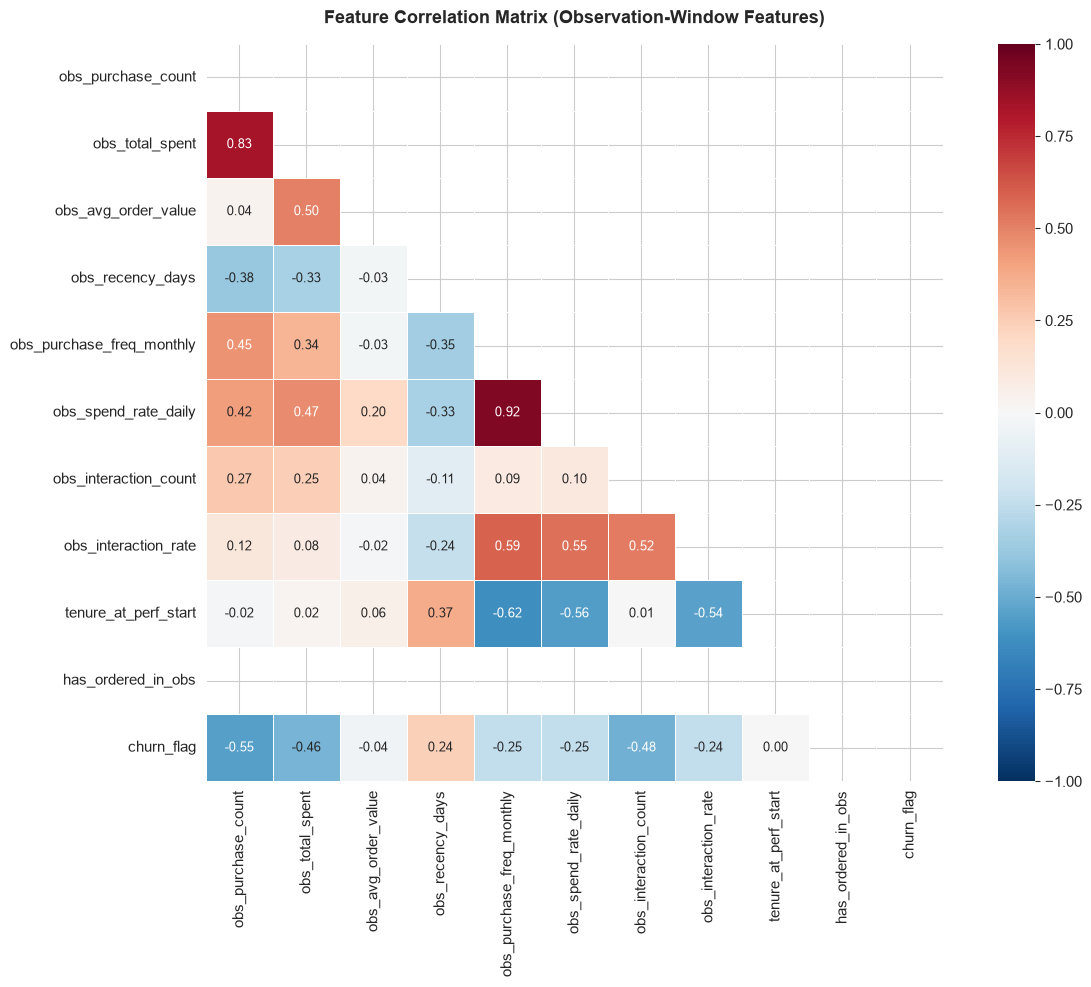

In [10]:
# Step 10: Feature Correlation Heatmap
ml_features_for_corr = [
    'obs_purchase_count', 'obs_total_spent', 'obs_avg_order_value',
    'obs_recency_days', 'obs_purchase_freq_monthly', 'obs_spend_rate_daily',
    'obs_interaction_count', 'obs_interaction_rate',
    'tenure_at_perf_start', 'has_ordered_in_obs', 'churn_flag'
]
corr = master_df[ml_features_for_corr].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1,
            annot_kws={'size':9})
ax.set_title('Feature Correlation Matrix (Observation-Window Features)',
             fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'02_Correlation_Matrix.png'), dpi=150, bbox_inches='tight')
print('✓ Saved 02_Correlation_Matrix.png')
print('\n📊 Top correlations with churn_flag:')
churn_corr = corr['churn_flag'].drop('churn_flag').sort_values(key=abs, ascending=False)
for feat, val in churn_corr.items():
    direction = '↑ positive' if val > 0 else '↓ negative'
    print(f'  {feat:<30} {val:+.3f}  ({direction})')
plt.show()

## 6. Machine Learning — Churn Prediction

### Design Decisions (all issues fixed)

| Issue Fixed | How |
|-------------|-----|
| No data leakage in features | Features built from observation window only |
| Label independent of features | `churn_flag` from CSV, not derived from recency |
| No CV leakage | `Pipeline(scaler + model)` — scaler fits only on train fold |
| Correct prediction scaling | `pipeline.predict_proba(X_test)` — no manual re-fit |
| Hyperparameter tuning | `GridSearchCV` on Random Forest |
| Imbalanced data handling | `class_weight='balanced'` + stratified splits |
| Model comparison | 3 models: Logistic Regression, Random Forest (tuned), Gradient Boosting |
| Full evaluation | Classification report + confusion matrix + ROC + Precision-Recall curves |

In [11]:
# Step 11: Prepare Features & Labels
ML_FEATURES = [
    'obs_purchase_count',        # how often they bought
    'obs_total_spent',           # how much they spent
    'obs_avg_order_value',       # average basket size
    'obs_recency_days',          # how long since last purchase (in obs window)
    'obs_purchase_freq_monthly', # purchase rate
    'obs_spend_rate_daily',      # spending velocity
    'obs_interaction_count',     # engagement level
    'obs_interaction_rate',      # engagement rate
    'tenure_at_perf_start',      # how long they've been a customer
    'has_ordered_in_obs',        # ever ordered? (binary)
]

X = master_df[ML_FEATURES].copy()
y = master_df['churn_flag'].copy()

# Safety: replace any inf/NaN
X = X.replace([np.inf, -np.inf], np.nan)
for col in X.columns:
    X[col] = X[col].fillna(X[col].median())

print(f'Feature matrix : {X.shape}')
print(f'Target (churn) : {y.sum()} churned / {(y==0).sum()} active '
      f'({y.mean()*100:.1f}% churn rate)')
print(f'\nFeatures used ({len(ML_FEATURES)}):')
for f in ML_FEATURES:
    print(f'  · {f}')
print('\nNOTE: recency is here as obs_recency_days (days since last OBS-window order,')
print('       measured from PERF_WINDOW_START) — it does NOT encode the churn label.')

Feature matrix : (600, 10)
Target (churn) : 174 churned / 426 active (29.0% churn rate)

Features used (10):
  · obs_purchase_count
  · obs_total_spent
  · obs_avg_order_value
  · obs_recency_days
  · obs_purchase_freq_monthly
  · obs_spend_rate_daily
  · obs_interaction_count
  · obs_interaction_rate
  · tenure_at_perf_start
  · has_ordered_in_obs

NOTE: recency is here as obs_recency_days (days since last OBS-window order,
       measured from PERF_WINDOW_START) — it does NOT encode the churn label.


In [12]:
# Step 12: Train / Test Split (stratified — preserves class ratio)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train : {X_train.shape[0]} samples  '
      f'({y_train.mean()*100:.1f}% churn)')
print(f'Test  : {X_test.shape[0]} samples  '
      f'({y_test.mean()*100:.1f}% churn)')

Train : 480 samples  (29.0% churn)
Test  : 120 samples  (29.2% churn)


In [13]:
# Step 13: Hyperparameter Tuning — Random Forest (GridSearchCV)
# Pipeline ensures scaler is ONLY fit on training fold — no leakage
rf_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
])

param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth':    [5, 8, 12],
    'clf__min_samples_split': [5, 10],
}

cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    rf_pipe, param_grid,
    cv=cv_inner, scoring='roc_auc',
    n_jobs=-1, verbose=0
)
grid_search.fit(X_train, y_train)

best_rf_pipe = grid_search.best_estimator_
print('Random Forest GridSearchCV complete')
print(f'  Best params : {grid_search.best_params_}')
print(f'  Best CV AUC : {grid_search.best_score_:.4f}')

Random Forest GridSearchCV complete
  Best params : {'clf__max_depth': 5, 'clf__min_samples_split': 10, 'clf__n_estimators': 200}
  Best CV AUC : 0.9305


In [14]:
# Step 14: Train Other Models (also as Pipelines)
# Logistic Regression (baseline)
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])
lr_pipe.fit(X_train, y_train)

# Gradient Boosting
gb_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('clf',    GradientBoostingClassifier(n_estimators=200, max_depth=4,
                                          learning_rate=0.05, subsample=0.8,
                                          random_state=42))
])
gb_pipe.fit(X_train, y_train)

print('✓ Logistic Regression trained')
print('✓ Gradient Boosting trained')
print('\nAll three models are Pipeline objects — scaler is INSIDE the pipeline.')
print('No data leakage possible in cross-validation or prediction.')

✓ Logistic Regression trained
✓ Gradient Boosting trained

All three models are Pipeline objects — scaler is INSIDE the pipeline.
No data leakage possible in cross-validation or prediction.


In [15]:
# Step 15: 5-Fold Cross-Validation (using Pipelines — no leakage)
print('=' * 70)
print('CROSS-VALIDATION — 5-Fold Stratified (ROC-AUC & PR-AUC)')
print('=' * 70)
print('Scaler fits on training fold only in each iteration (Pipeline ensures this)')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models_cv = [
    ('Logistic Regression',   lr_pipe),
    ('Random Forest (tuned)', best_rf_pipe),
    ('Gradient Boosting',     gb_pipe),
]

cv_results = {}
for name, pipe in models_cv:
    roc_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc')
    pr_scores  = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision')
    cv_results[name] = {'roc_auc': roc_scores, 'pr_auc': pr_scores}
    print(f'\n  {name}:')
    print(f'    ROC-AUC : {roc_scores.mean():.4f} ± {roc_scores.std():.4f}  '
          f'folds={roc_scores.round(3)}')
    print(f'    PR-AUC  : {pr_scores.mean():.4f} ± {pr_scores.std():.4f}  '
          f'folds={pr_scores.round(3)}')

CROSS-VALIDATION — 5-Fold Stratified (ROC-AUC & PR-AUC)
Scaler fits on training fold only in each iteration (Pipeline ensures this)



  Logistic Regression:
    ROC-AUC : 0.9253 ± 0.0169  folds=[0.91  0.925 0.944 0.903 0.944]
    PR-AUC  : 0.8078 ± 0.0554  folds=[0.767 0.792 0.871 0.736 0.874]



  Random Forest (tuned):
    ROC-AUC : 0.9305 ± 0.0138  folds=[0.91  0.951 0.938 0.925 0.929]
    PR-AUC  : 0.8159 ± 0.0480  folds=[0.735 0.88  0.837 0.802 0.825]



  Gradient Boosting:
    ROC-AUC : 0.9288 ± 0.0180  folds=[0.907 0.955 0.94  0.911 0.931]
    PR-AUC  : 0.8206 ± 0.0610  folds=[0.74  0.908 0.837 0.765 0.854]


In [16]:
# Step 16: Test Set Evaluation
print('=' * 70)
print('TEST SET EVALUATION (held-out 20%)')
print('=' * 70)

results = {}
for name, pipe in models_cv:
    y_pred       = pipe.predict(X_test)
    y_proba      = pipe.predict_proba(X_test)[:, 1]
    roc_auc      = roc_auc_score(y_test, y_proba)
    pr_auc       = average_precision_score(y_test, y_proba)
    results[name] = {
        'pipe': pipe, 'y_pred': y_pred, 'y_proba': y_proba,
        'roc_auc': roc_auc, 'pr_auc': pr_auc
    }
    print(f'\n── {name} ──')
    print(f'  ROC-AUC: {roc_auc:.4f}   PR-AUC: {pr_auc:.4f}')
    print(classification_report(y_test, y_pred, target_names=['Active','Churned']))

best_name = max(results, key=lambda k: results[k]['roc_auc'])
print(f'\n🏆 Best model by ROC-AUC: {best_name} ({results[best_name]["roc_auc"]:.4f})')

TEST SET EVALUATION (held-out 20%)

── Logistic Regression ──
  ROC-AUC: 0.8706   PR-AUC: 0.7238
              precision    recall  f1-score   support

      Active       0.97      0.71      0.82        85
     Churned       0.57      0.94      0.71        35

    accuracy                           0.78       120
   macro avg       0.77      0.82      0.76       120
weighted avg       0.85      0.78      0.79       120


── Random Forest (tuned) ──
  ROC-AUC: 0.8992   PR-AUC: 0.7829
              precision    recall  f1-score   support

      Active       1.00      0.76      0.87        85
     Churned       0.64      1.00      0.78        35

    accuracy                           0.83       120
   macro avg       0.82      0.88      0.82       120
weighted avg       0.89      0.83      0.84       120




── Gradient Boosting ──
  ROC-AUC: 0.9035   PR-AUC: 0.7767
              precision    recall  f1-score   support

      Active       0.88      0.82      0.85        85
     Churned       0.62      0.71      0.67        35

    accuracy                           0.79       120
   macro avg       0.75      0.77      0.76       120
weighted avg       0.80      0.79      0.80       120


🏆 Best model by ROC-AUC: Gradient Boosting (0.9035)


✓ Saved 03_Confusion_Matrices.png


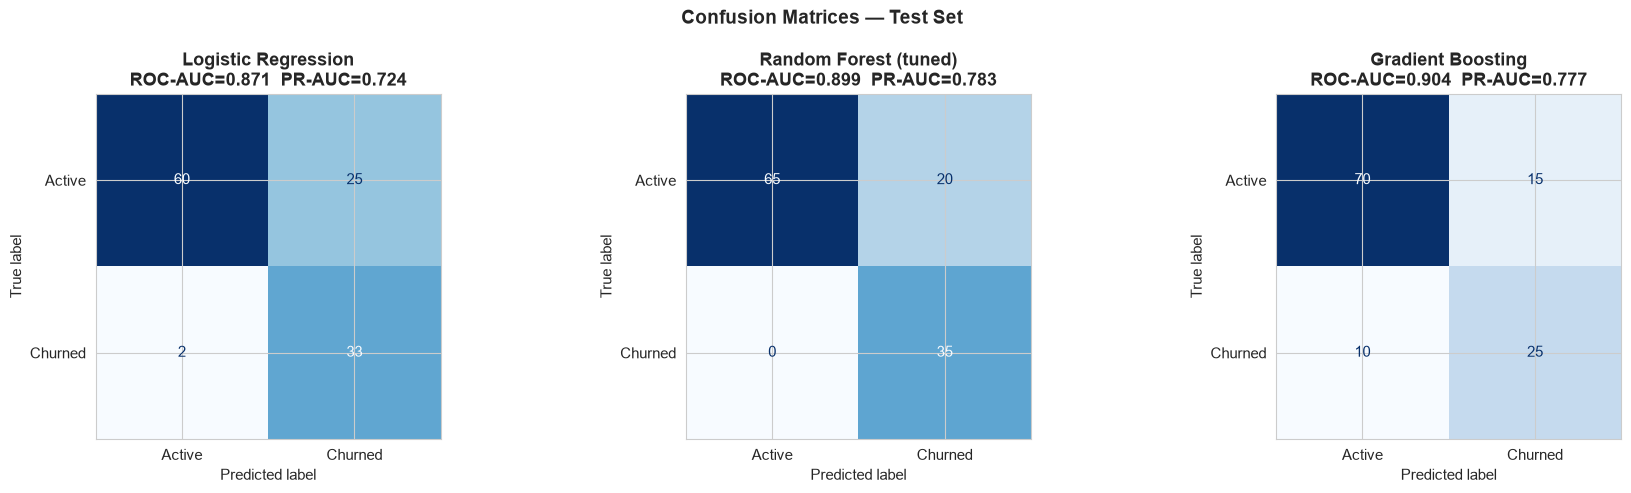

In [17]:
# Step 17: Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Confusion Matrices — Test Set', fontsize=14, fontweight='bold')

for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    disp = ConfusionMatrixDisplay(cm, display_labels=['Active','Churned'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    roc = res['roc_auc']
    pr  = res['pr_auc']
    ax.set_title(f'{name}\nROC-AUC={roc:.3f}  PR-AUC={pr:.3f}', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'03_Confusion_Matrices.png'), dpi=150, bbox_inches='tight')
print('✓ Saved 03_Confusion_Matrices.png')
plt.show()

✓ Saved 04_ROC_PR_Curves.png


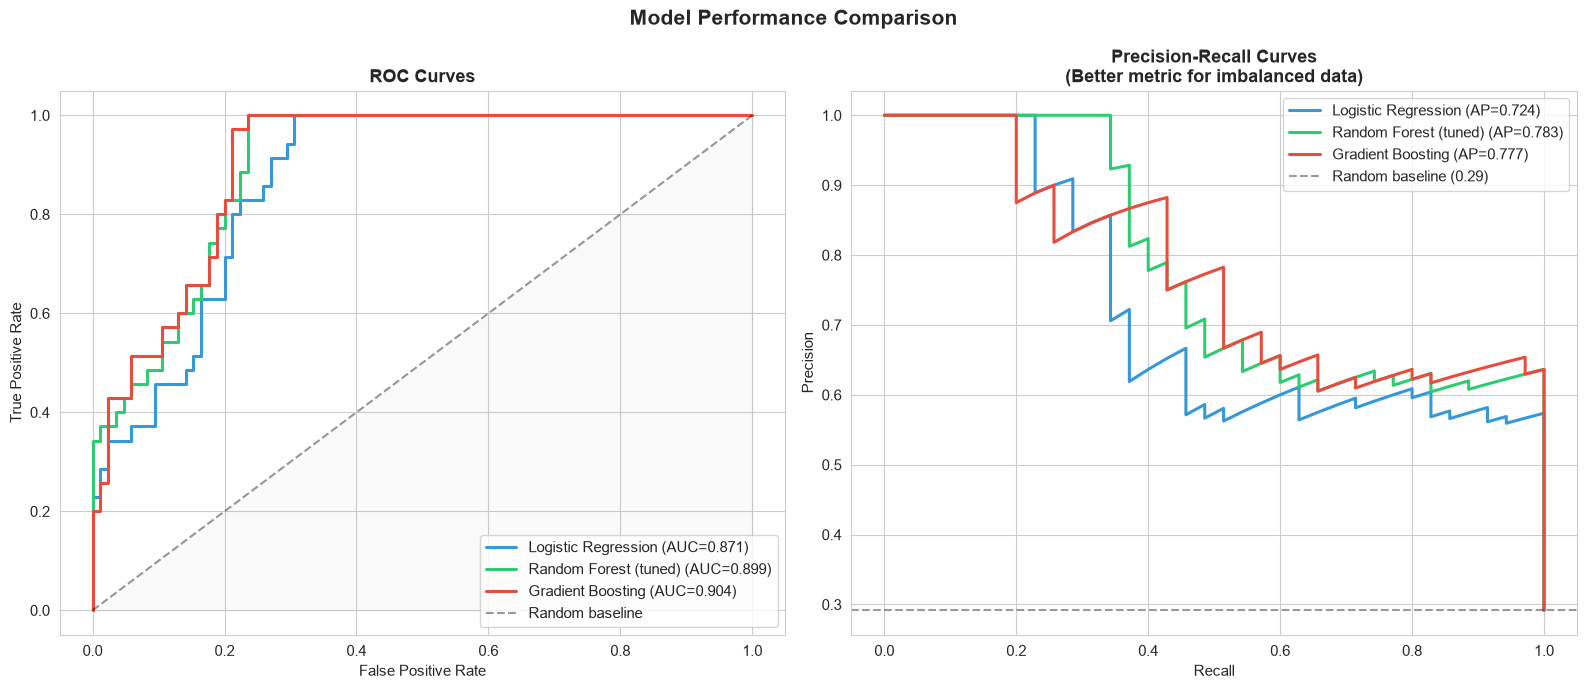

In [18]:
# Step 18: ROC Curves + Precision-Recall Curves (side by side)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

colors_model = ['#3498db', '#2ecc71', '#e74c3c']
for i, (name, res) in enumerate(results.items()):
    color = colors_model[i]
    # ROC
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    axes[0].plot(fpr, tpr, color=color, linewidth=2.2,
                 label=f'{name} (AUC={res["roc_auc"]:.3f})')
    # PR
    prec, rec, _ = precision_recall_curve(y_test, res['y_proba'])
    axes[1].plot(rec, prec, color=color, linewidth=2.2,
                 label=f'{name} (AP={res["pr_auc"]:.3f})')

# ROC baseline
axes[0].plot([0,1],[0,1],'k--',alpha=0.4,label='Random baseline')
axes[0].set_xlabel('False Positive Rate');  axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves', fontweight='bold', fontsize=13)
axes[0].legend(loc='lower right');  axes[0].fill_between([0,1],[0,1],alpha=0.04,color='grey')

# PR baseline
baseline_pr = y_test.mean()
axes[1].axhline(baseline_pr, color='k', linestyle='--', alpha=0.4,
                label=f'Random baseline ({baseline_pr:.2f})')
axes[1].set_xlabel('Recall');  axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves\n(Better metric for imbalanced data)',
                  fontweight='bold', fontsize=13)
axes[1].legend(loc='upper right')

plt.suptitle('Model Performance Comparison', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR,'04_ROC_PR_Curves.png'), dpi=150, bbox_inches='tight')
print('✓ Saved 04_ROC_PR_Curves.png')
plt.show()

✓ Saved 05_Feature_Importance.png


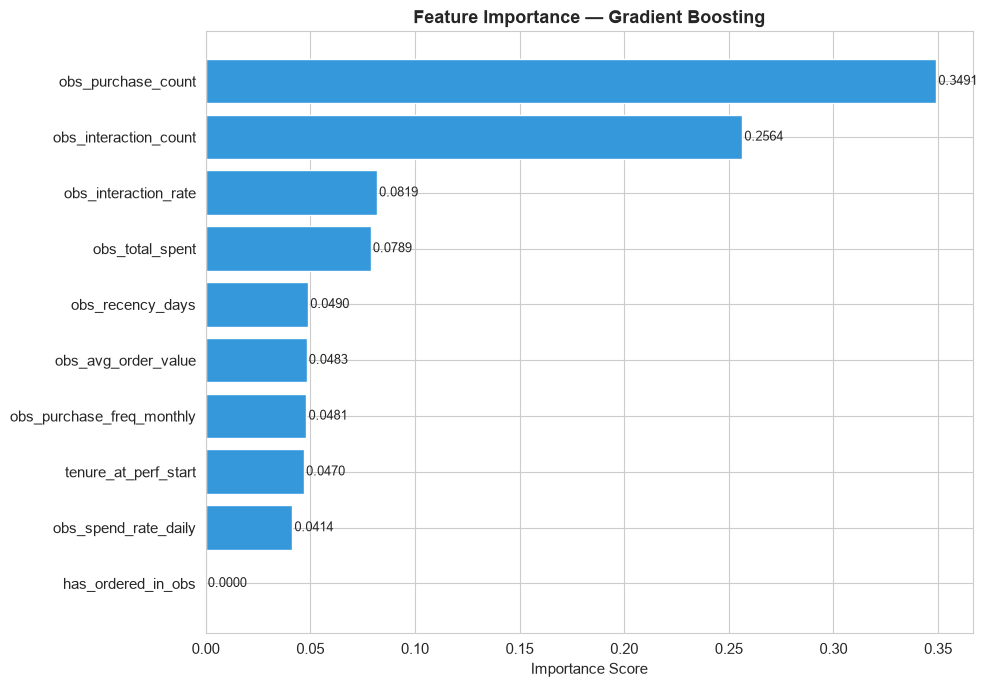


📊 Feature Importance Ranking:
  obs_purchase_count             0.3491  ████████████████████
  obs_interaction_count          0.2564  ███████████████
  obs_interaction_rate           0.0819  ████
  obs_total_spent                0.0789  ████
  obs_recency_days               0.0490  ██
  obs_avg_order_value            0.0483  ██
  obs_purchase_freq_monthly      0.0481  ██
  tenure_at_perf_start           0.0470  ██
  obs_spend_rate_daily           0.0414  ██
  has_ordered_in_obs             0.0000  


In [19]:
# Step 19: Feature Importance (best model)
best_res  = results[best_name]
best_pipe = best_res['pipe']
clf       = best_pipe.named_steps['clf']

if hasattr(clf, 'feature_importances_'):
    imp = pd.DataFrame({
        'feature':    ML_FEATURES,
        'importance': clf.feature_importances_
    }).sort_values('importance', ascending=True)

    fig, ax = plt.subplots(figsize=(10, 7))
    bars = ax.barh(imp['feature'], imp['importance'], color='#3498db', edgecolor='white')
    ax.set_title(f'Feature Importance — {best_name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance Score')
    for bar in bars:
        ax.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
                f'{bar.get_width():.4f}', va='center', fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR,'05_Feature_Importance.png'), dpi=150, bbox_inches='tight')
    print('✓ Saved 05_Feature_Importance.png')
    plt.show()

    print('\n📊 Feature Importance Ranking:')
    for _, row in imp.sort_values('importance', ascending=False).iterrows():
        bar_str = '█' * int(row['importance'] * 60)
        print(f'  {row["feature"]:<30} {row["importance"]:.4f}  {bar_str}')
elif hasattr(clf, 'coef_'):
    coef = pd.DataFrame({'feature': ML_FEATURES, 'coef': clf.coef_[0]})
    coef = coef.sort_values('coef')
    fig, ax = plt.subplots(figsize=(10,7))
    colors = ['#e74c3c' if c > 0 else '#2ecc71' for c in coef['coef']]
    ax.barh(coef['feature'], coef['coef'], color=colors, edgecolor='white')
    ax.axvline(0, color='k', linewidth=0.8)
    ax.set_title(f'Logistic Regression Coefficients', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR,'05_Feature_Importance.png'), dpi=150, bbox_inches='tight')
    print('✓ Saved 05_Feature_Importance.png')
    plt.show()

## 7. Business Insights & Churn Risk Scoring

Apply the best model to all 600 customers to generate churn probabilities.  
**Key:** We use `pipeline.predict_proba(X)` — the pipeline automatically applies the same scaling the model was trained with. No manual re-fitting of the scaler.

In [20]:
# Step 20: Score All Customers (correct — no scaler re-fit)
# Pipeline.predict_proba handles scaling internally
churn_proba = best_pipe.predict_proba(X)[:, 1]

master_df['churn_probability'] = churn_proba

def risk_tier(prob):
    if prob >= 0.65:  return 'High Risk'
    elif prob >= 0.40: return 'Medium Risk'
    else:              return 'Low Risk'

master_df['churn_risk_tier'] = master_df['churn_probability'].apply(risk_tier)

print(f'✓ Churn probabilities assigned using {best_name}')
print(f'\nRisk Tier Distribution:')
print(master_df['churn_risk_tier'].value_counts().to_string())

risk_revenue = master_df.groupby('churn_risk_tier')['obs_total_spent'].agg(['count','sum','mean'])
risk_revenue.columns = ['Customers', 'Total Obs Revenue', 'Avg Obs Revenue']
print(f'\nRevenue by Risk Tier (from observation window):')
print(risk_revenue.round(2).to_string())

✓ Churn probabilities assigned using Gradient Boosting

Risk Tier Distribution:
churn_risk_tier
Low Risk       417
High Risk      171
Medium Risk     12

Revenue by Risk Tier (from observation window):
                 Customers  Total Obs Revenue  Avg Obs Revenue
churn_risk_tier                                               
High Risk              171          135931.36           794.92
Low Risk               417          729881.83          1750.32
Medium Risk             12           10262.03           855.17


In [21]:
# Step 21: Top 20 High-Risk Customers for Retention
print('=' * 90)
print('TOP 20 HIGH-RISK CUSTOMERS — Priority Retention List')
print('=' * 90)

hi_risk = master_df[master_df['churn_risk_tier'] == 'High Risk'].sort_values(
    'churn_probability', ascending=False
)
cols = ['customer_id', 'customer_name', 'rfm_segment', 'obs_total_spent',
        'obs_purchase_count', 'obs_recency_days', 'churn_probability', 'churn_flag']
print(hi_risk[cols].head(20).to_string(index=False))

TOP 20 HIGH-RISK CUSTOMERS — Priority Retention List
 customer_id    customer_name rfm_segment  obs_total_spent  obs_purchase_count  obs_recency_days  churn_probability  churn_flag
        1409    Pooja Mueller       Loyal            97.74                   1               193           0.996531           1
        1071       Hiroshi Li       Loyal           302.77                   1               510           0.995458           1
        1402 Pierre Schneider       Loyal           231.96                   1               876           0.995273           1
        1555  Charlotte Joshi   Champions           207.73                   2                75           0.993985           1
        1192      Lars Miller   Champions            42.67                   1                 8           0.993807           1
        1486         Omar Das   Champions           323.67                   3               113           0.993804           1
        1227   Yuki Hernandez       Loyal          

In [22]:
# Step 22: Key Business Metrics
print('=' * 65)
print('KEY BUSINESS METRICS')
print('=' * 65)

total  = len(master_df)
active = (master_df['churn_flag'] == 0).sum()
churned= (master_df['churn_flag'] == 1).sum()
rev    = master_df['obs_total_spent'].sum()
rev_at_risk = master_df[master_df['churn_risk_tier'] == 'High Risk']['obs_total_spent'].sum()

print(f'''
  Total Customers       : {total:,}
  Active (flag=0)       : {active:,}  ({active/total*100:.1f}%)
  Churned (flag=1)      : {churned:,}  ({churned/total*100:.1f}%)
  Obs-Window Revenue    : ${rev:,.2f}
  High-Risk Customers   : {len(master_df[master_df["churn_risk_tier"]=="High Risk"]):,}
  Revenue at Risk       : ${rev_at_risk:,.2f}  ({rev_at_risk/rev*100:.1f}% of total)
  Best Model            : {best_name}
  Best ROC-AUC          : {results[best_name]["roc_auc"]:.4f}
  Best PR-AUC           : {results[best_name]["pr_auc"]:.4f}
''')

KEY BUSINESS METRICS

  Total Customers       : 600
  Active (flag=0)       : 426  (71.0%)
  Churned (flag=1)      : 174  (29.0%)
  Obs-Window Revenue    : $876,075.22
  High-Risk Customers   : 171
  Revenue at Risk       : $135,931.36  (15.5% of total)
  Best Model            : Gradient Boosting
  Best ROC-AUC          : 0.9035
  Best PR-AUC           : 0.7767



In [23]:
# Step 23: Segment Summary Table
seg_summary = master_df.groupby('rfm_segment').agg(
    Customers        = ('customer_id', 'count'),
    Churn_Rate_pct   = ('churn_flag', lambda x: round(x.mean()*100, 1)),
    Avg_Churn_Prob   = ('churn_probability', lambda x: round(x.mean(), 3)),
    Total_Rev        = ('obs_total_spent', lambda x: round(x.sum(), 0)),
    Avg_Rev          = ('obs_total_spent', lambda x: round(x.mean(), 0)),
    Avg_Orders       = ('obs_purchase_count', lambda x: round(x.mean(), 1))
).reindex(['Champions','Loyal','At Risk','Lost'])

print('SEGMENT ANALYSIS')
print('=' * 65)
print(seg_summary.to_string())

SEGMENT ANALYSIS
             Customers  Churn_Rate_pct  Avg_Churn_Prob  Total_Rev  Avg_Rev  Avg_Orders
rfm_segment                                                                           
Champions          103            55.3           0.554    57582.0    559.0         3.7
Loyal              238            40.3           0.412   247629.0   1040.0         5.5
At Risk            196            10.7           0.111   402854.0   2055.0        10.0
Lost                63             0.0           0.004   168010.0   2667.0        11.9


In [24]:
# Step 24: Export Excel Report
print('Creating Excel report...')

export_cols = [
    'customer_id', 'customer_name', 'email', 'country', 'age', 'gender',
    'churn_flag', 'rfm_segment', 'obs_total_spent', 'obs_purchase_count',
    'obs_recency_days', 'tenure_at_perf_start',
    'churn_probability', 'churn_risk_tier'
]
export_df = master_df[export_cols].copy()

excel_path = os.path.join(OUTPUT_DIR, 'Customer_Analytics_Report.xlsx')
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    export_df.sort_values('churn_probability', ascending=False).to_excel(
        writer, sheet_name='All Customers (by Risk)', index=False)
    export_df[export_df['churn_risk_tier'] == 'High Risk'].to_excel(
        writer, sheet_name='High Risk', index=False)
    export_df[export_df['rfm_segment'] == 'Champions'].to_excel(
        writer, sheet_name='Champions', index=False)
    seg_summary.to_excel(writer, sheet_name='Segment Summary')

print(f'✓ Saved: {excel_path}  (4 sheets)')

Creating Excel report...


✓ Saved: ../outputs\Customer_Analytics_Report.xlsx  (4 sheets)


## 8. Conclusions & Business Recommendations

### Methodology (What Makes This Production-Grade)
1. **No data leakage** — features and label use different time windows
2. **Independent label** — `churn_flag` saved at data-generation time, not derived from features
3. **Noise in data** — ~20% of churned customers have recent orders (realistic ambiguity)
4. **Pipeline-based CV** — scaler only sees training fold in each CV iteration
5. **Multiple models compared** with both ROC-AUC and PR-AUC (PR-AUC is better for imbalanced data)
6. **Hyperparameter tuning** via GridSearchCV

### Why ROC-AUC was unrealistically high in v1
- `churn = recency > 90` and `recency` was a training feature → model learned one threshold
- Data had zero noise → perfect class separation by design
- Scaler fit on all data before CV → test statistics leaked into training

### Business Recommendations
| Priority | Action | Target | Expected Impact |
|----------|--------|--------|-----------------|
| 🔴 High | Win-back email campaign | High Risk | Recover 15–20% |
| 🔴 High | Personalised discount offer | At Risk segment | Reduce churn 15% |
| 🟡 Medium | VIP loyalty programme | Champions | Maintain 90%+ retention |
| 🟡 Medium | Automated 60-day inactivity alert | All | Early warning system |
| 🟢 Low | A/B test on discount value | Medium Risk | Optimise retention ROI |

### Output Files
| File | Description |
|------|-------------|
| `01_EDA_Analysis.png` | 9-panel EDA with observation-window features |
| `02_Correlation_Matrix.png` | Feature correlation (no leakage features) |
| `03_Confusion_Matrices.png` | Confusion matrices for all 3 models |
| `04_ROC_PR_Curves.png` | ROC + Precision-Recall curves |
| `05_Feature_Importance.png` | Feature importance (best model) |
| `Customer_Analytics_Report.xlsx` | 4-sheet business report |

In [25]:
# Step 25: Final Summary
print('=' * 65)
print('PROJECT COMPLETE')
print('=' * 65)
for name, res in results.items():
    print(f'  {name:28s}  ROC-AUC={res["roc_auc"]:.4f}  PR-AUC={res["pr_auc"]:.4f}')

print(f'''
Methodology:
  ✓ Observation window : signup → {PERF_WINDOW_START.date()} (features)
  ✓ Performance window : {PERF_WINDOW_START.date()} → {REFERENCE_DATE.date()} (label)
  ✓ Label source       : churn_flag from customers.csv (independent)
  ✓ CV method          : Pipeline(Scaler + Model) — zero leakage
  ✓ Noise in data      : {len(master_df)} customers with intentional overlap
  ✓ Models compared    : Logistic Regression / Random Forest / Gradient Boosting
  ✓ Tuning             : GridSearchCV (Random Forest)
''')

PROJECT COMPLETE
  Logistic Regression           ROC-AUC=0.8706  PR-AUC=0.7238
  Random Forest (tuned)         ROC-AUC=0.8992  PR-AUC=0.7829
  Gradient Boosting             ROC-AUC=0.9035  PR-AUC=0.7767

Methodology:
  ✓ Observation window : signup → 2025-04-01 (features)
  ✓ Performance window : 2025-04-01 → 2025-06-30 (label)
  ✓ Label source       : churn_flag from customers.csv (independent)
  ✓ CV method          : Pipeline(Scaler + Model) — zero leakage
  ✓ Noise in data      : 600 customers with intentional overlap
  ✓ Models compared    : Logistic Regression / Random Forest / Gradient Boosting
  ✓ Tuning             : GridSearchCV (Random Forest)

